## Team Members

| # | Name | GitHub |
|---|------|--------|
| 1 | Rohima Ahmed Ibrahim | [rohimaahmed101-sys](https://github.com/rohimaahmed101-sys) |
| 2 | Shaimaa Kotit | [shaimaakotit-29](https://github.com/shaimaakotit-29) |
| 3 | Doha Mahmoud | [dohaalaraby-lang](https://github.com/dohaalaraby-lang) |
|4  | Radwa Sabry | [RadwaSabry1](https://github.com/RadwaSabry1)|

**Dataset:** [Skin Cancer MNIST: HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000)

# AIE231 Course Project: Phase 1 dataset eligibility check (HAM10000)

**Dataset:** [Skin Cancer MNIST: HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000) (Kaggle, `kmader/skin-cancer-mnist-ham10000`)
**Original source:** Tschandl, P., Rosendahl, C. & Kittler, H. *The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions.* Sci. Data 5, 180161 (2018). https://doi.org/10.1038/sdata.2018.161 (licence: CC BY-NC 4.0)

## Why this notebook exists
The specification (page 3) says the dataset sizes must be verified by the team itself: *"Verify them yourself in your EDA."* This notebook counts everything from the real files so the tracker items below can be closed with evidence, not with numbers copied from a web page.

| Checklist item | Spec rule | Checked in |
|---|---|---|
| **D1** | Images: at least 5,000 | Check 2 |
| **D2** | At least 3 classes, or binary with clear imbalance | Check 3 |
| **D3** | At least one real-world imperfection (imbalance, missing values, duplicates, varying image size or quality) | Checks 3, 5, 6, 7 |
| Group split (spec 3.2) | Samples from the same source stay in the same split | Check 4 |
| EDA (spec 3.1, P3) | Sample images per class | Check 8 |

## What this notebook does NOT do
- It does **not** split the data, train any model, or change any file. It only reads.
- It is a Phase 1 check. In Phase 2 the reusable parts move into `src/data.py`, and `notebooks/01_eda.ipynb` will import from there, as the spec requires.

## How to run
1. Kaggle → **Settings → API → Generate New Token**, and copy the token.
2. Add it to Colab Secrets as `KAGGLE_API_TOKEN` (Step 1 explains how).
3. In Colab: **Runtime → Run all**.
4. When it finishes, download `phase1_summary.json` (Files panel on the left) and send the outputs of every cell back for review.

## Step 1: Kaggle credentials (safe way: Colab Secrets)
The token is **never** written inside the notebook, so it cannot leak if the notebook is shared or pushed to GitHub.

**One-time setup:**
1. Click the **key icon (Secrets)** in Colab's left sidebar.
2. **Add new secret**. Name: `KAGGLE_API_TOKEN`. Value: your Kaggle token (the one that starts with `KGAT_`).
3. Turn on **Notebook access** for it.

If you have an old-style `kaggle.json` file instead, this cell will ask you to upload it.

In [1]:
# Step 1: load the Kaggle token from Colab Secrets (fallback: upload kaggle.json)
import os
from pathlib import Path

try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle token loaded from Colab Secrets.")
except Exception as err:
    print("No KAGGLE_API_TOKEN secret found (", type(err).__name__, "). Falling back to kaggle.json upload.")
    kaggle_dir = Path.home() / ".kaggle"
    token = kaggle_dir / "kaggle.json"
    if not token.exists():
        from google.colab import files
        files.upload()  # choose kaggle.json
        kaggle_dir.mkdir(parents=True, exist_ok=True)
        Path("kaggle.json").rename(token)
    os.chmod(token, 0o600)
    print("kaggle.json ready.")

Kaggle token loaded from Colab Secrets.


## Step 2: Download the dataset
Uses `kagglehub`, Kaggle's official download library. About 3 GB the first time; after that it is reused from the cache.

In [2]:
# Step 2: download HAM10000 from Kaggle
!pip install -q --upgrade kagglehub
import kagglehub

DATA_DIR = Path(kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000"))
print("Dataset folder:", DATA_DIR)
for item in sorted(DATA_DIR.iterdir()):
    print("  ", item.name)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset folder: /kaggle/input/skin-cancer-mnist-ham10000
   HAM10000_images_part_1
   HAM10000_images_part_2
   HAM10000_metadata.csv
   ham10000_images_part_1
   ham10000_images_part_2
   hmnist_28_28_L.csv
   hmnist_28_28_RGB.csv
   hmnist_8_8_L.csv
   hmnist_8_8_RGB.csv


## Step 3: Imports and settings
Only the libraries the spec expects for data work: pandas, NumPy, Matplotlib (plus Pillow to read image headers). The random seed fixes which sample images are shown in Check 8, so the figure is reproducible.

In [3]:
# Step 3: imports and settings
import hashlib
import json
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

SEED = 42
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
SUMMARY = {}  # every fact below is stored here and saved to phase1_summary.json at the end

# Full names of the 7 diagnostic codes (Tschandl et al., 2018)
DX_NAMES = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions",
}

# Plot style: one hue, thin marks, quiet axes
BAR = "#2a78d6"
INK, QUIET = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": QUIET, "axes.labelcolor": INK, "xtick.color": QUIET, "ytick.color": QUIET,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
print("Ready. Data folder:", DATA_DIR)

Ready. Data folder: /kaggle/input/skin-cancer-mnist-ham10000


## Check 1: Metadata file
`HAM10000_metadata.csv` has one row per image. Its columns: `lesion_id` (which skin lesion), `image_id` (which photo), `dx` (the label), `dx_type` (how the diagnosis was confirmed), `age`, `sex`, `localization` (body site).

**Looking for:** the row count, and whether any `image_id` appears twice (a duplicated record).

In [4]:
# Check 1: metadata
meta_path = next(p for p in DATA_DIR.rglob("*.csv") if p.name.lower() == "ham10000_metadata.csv")
meta = pd.read_csv(meta_path)

dup_rows = int(meta["image_id"].duplicated().sum())
SUMMARY["metadata_rows"] = int(len(meta))
SUMMARY["metadata_columns"] = list(meta.columns)
SUMMARY["duplicated_image_id_rows"] = dup_rows

print("Metadata file:", meta_path)
print("Rows:", len(meta))
print("Columns:", list(meta.columns))
print("Duplicated image_id rows:", dup_rows)
meta.head()

Metadata file: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Rows: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Duplicated image_id rows: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


## Check 2: Image files (D1: at least 5,000 images)
Counts the image files on disk and matches them to the metadata.

**Looking for:**
- the number of **unique** images (this is the number that must be at least 5,000);
- images stored in more than one folder (the Kaggle copy may hold the same file twice; we must not count it twice);
- metadata rows with no image, or images with no metadata row.

In [5]:
# Check 2: image files
images = defaultdict(list)  # image_id -> every path that holds it
for p in DATA_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES:
        images[p.stem].append(p)

n_files = sum(len(v) for v in images.values())
multi_copy = {k: v for k, v in images.items() if len(v) > 1}
meta_ids = set(meta["image_id"])
no_file = sorted(meta_ids - set(images))
no_meta = sorted(set(images) - meta_ids)

SUMMARY.update(image_files=n_files, unique_image_ids=len(images), ids_with_multiple_files=len(multi_copy),
               metadata_rows_without_image=len(no_file), images_without_metadata=len(no_meta))

print("Image files on disk:            ", n_files)
print("Unique image IDs:               ", len(images))
print("IDs stored in more than 1 file: ", len(multi_copy))
if multi_copy:
    k, v = next(iter(multi_copy.items()))
    print("   example:", k, "->", [str(x.parent.name) for x in v])
print("Metadata rows without an image: ", len(no_file))
print("Images without a metadata row:  ", len(no_meta))
print()
print("D1 (>= 5,000 unique images):", "MET" if len(images) >= 5000 else "NOT MET")

Image files on disk:             20030
Unique image IDs:                10015
IDs stored in more than 1 file:  10015
   example: ISIC_0028933 -> ['HAM10000_images_part_1', 'ham10000_images_part_1']
Metadata rows without an image:  0
Images without a metadata row:   0

D1 (>= 5,000 unique images): MET


## Check 3: Classes (D2: at least 3 classes; D3: imbalance)
Counts images per diagnosis.

**Looking for:**
- the number of classes;
- the **imbalance ratio** (largest class ÷ smallest class);
- the **majority-class share**: the accuracy a model would get by always predicting the biggest class. This is a preview of the trivial baseline (B1) and shows why plain accuracy would be a misleading metric here. (The real baseline is measured later on the validation set, not on the whole dataset.)

                                                name  images  percent
dx                                                                   
nv                                  Melanocytic nevi    6705    66.95
mel                                         Melanoma    1113    11.11
bkl                    Benign keratosis-like lesions    1099    10.97
bcc                             Basal cell carcinoma     514     5.13
akiec  Actinic keratoses / intraepithelial carcinoma     327     3.27
vasc                                Vascular lesions     142     1.42
df                                    Dermatofibroma     115     1.15

Number of classes: 7
Imbalance ratio (largest / smallest): 58.3
Always-predict-majority accuracy (whole dataset): 0.6695
D2 (>= 3 classes): MET


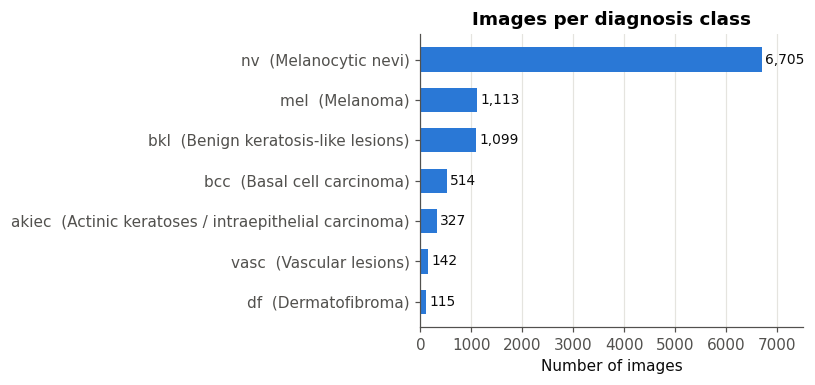

In [6]:
# Check 3: class distribution
counts = meta["dx"].value_counts()
table = pd.DataFrame({
    "name": [DX_NAMES.get(c, "?") for c in counts.index],
    "images": counts.values,
    "percent": (counts.values / counts.sum() * 100).round(2),
}, index=counts.index)

ratio = round(float(counts.max() / counts.min()), 2)
majority_share = round(float(counts.max() / counts.sum()), 4)
SUMMARY.update(class_counts={k: int(v) for k, v in counts.items()}, n_classes=int(counts.size),
               imbalance_ratio=ratio, majority_class_share=majority_share)

print(table.to_string())
print()
print("Number of classes:", counts.size)
print("Imbalance ratio (largest / smallest):", ratio)
print("Always-predict-majority accuracy (whole dataset):", majority_share)
print("D2 (>= 3 classes):", "MET" if counts.size >= 3 else "NOT MET")

# Figure: images per class, largest first
fig, ax = plt.subplots(figsize=(7.5, 3.6))
order = counts.sort_values()
labels = [f"{c}  ({DX_NAMES.get(c, '?')})" for c in order.index]
ax.barh(labels, order.values, color=BAR, height=0.6)
for y, v in enumerate(order.values):
    ax.text(v + counts.max() * 0.01, y, f"{v:,}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Number of images")
ax.set_title("Images per diagnosis class")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

## Check 4: Lesion groups (spec 3.2: group split)
One skin lesion can have several photos (for example taken at different magnifications). If photos of the **same lesion** land in both the training set and the test set, the model is tested on something it has effectively already seen, and the test score is inflated. That is data leakage.

The spec says: *"If several samples come from the same person or source, keep them in the same split."* So the split must be done by `lesion_id`, not by image.

**Looking for:** how many unique lesions exist, how many have more than one image, and whether any lesion carries two different labels (that would be label noise).

Unique lesions: 7470
Lesions with more than one image: 1956 (holding 4501 images)
Lesions whose images have different labels: 0

Images per lesion -> number of lesions
image_id
1    5514
2    1423
3     490
4      34
5       5
6       4


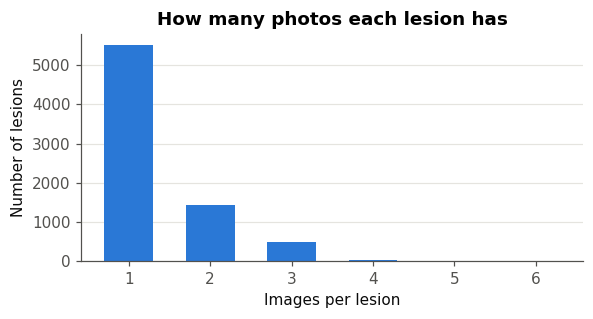

In [7]:
# Check 4: lesion groups
per_lesion = meta.groupby("lesion_id")["image_id"].count()
dist = per_lesion.value_counts().sort_index()
multi = int((per_lesion > 1).sum())
imgs_in_multi = int(per_lesion[per_lesion > 1].sum())
mixed = int((meta.groupby("lesion_id")["dx"].nunique() > 1).sum())

SUMMARY.update(unique_lesions=int(per_lesion.size), lesions_with_multiple_images=multi,
               images_in_multi_image_lesions=imgs_in_multi, lesions_with_mixed_labels=mixed,
               images_per_lesion_distribution={int(k): int(v) for k, v in dist.items()})

print("Unique lesions:", per_lesion.size)
print("Lesions with more than one image:", multi, f"(holding {imgs_in_multi} images)")
print("Lesions whose images have different labels:", mixed)
print()
print("Images per lesion -> number of lesions")
print(dist.to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.0))
ax.bar(dist.index.astype(str), dist.values, color=BAR, width=0.6)
ax.set_xlabel("Images per lesion")
ax.set_ylabel("Number of lesions")
ax.set_title("How many photos each lesion has")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Check 5: Missing and "unknown" values (D3)
Some metadata fields are empty (NaN) and some hold the word "unknown". Both count as missing. They matter only if we use the metadata as model input; the images themselves are the main input.

`dx_type` shows how each label was confirmed (for example histopathology vs. follow-up vs. expert consensus). Labels confirmed by expert consensus can be less certain, which is useful later in the error analysis.

In [8]:
# Check 5: missing / unknown values
nan_counts = meta.isna().sum()
unknown_counts = meta.astype(str).apply(lambda c: c.str.strip().str.lower().eq("unknown")).sum()
missing_table = pd.DataFrame({"missing (NaN)": nan_counts, "'unknown'": unknown_counts})
dx_type_counts = meta["dx_type"].value_counts()

SUMMARY["missing_values"] = {k: int(v) for k, v in nan_counts.items()}
SUMMARY["unknown_values"] = {k: int(v) for k, v in unknown_counts.items()}
SUMMARY["dx_type_counts"] = {k: int(v) for k, v in dx_type_counts.items()}

print(missing_table.to_string())
print()
print("How the diagnosis was confirmed (dx_type):")
print(dx_type_counts.to_string())

              missing (NaN)  'unknown'
lesion_id                 0          0
image_id                  0          0
dx                        0          0
dx_type                   0          0
age                      57          0
sex                       0         57
localization              0        234

How the diagnosis was confirmed (dx_type):
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69


## Check 6: Image sizes and colour modes (D3)
Reads only each image's header (fast). Models need one fixed input size, so if sizes differ, resizing becomes a documented preprocessing step.

In [9]:
# Check 6: image sizes
sizes, modes, unreadable = Counter(), Counter(), []
for image_id, paths in images.items():
    try:
        with Image.open(paths[0]) as img:
            sizes[img.size] += 1
            modes[img.mode] += 1
    except OSError:
        unreadable.append(image_id)

SUMMARY["image_sizes"] = {f"{w}x{h}": n for (w, h), n in sizes.most_common()}
SUMMARY["colour_modes"] = dict(modes)
SUMMARY["unreadable_images"] = unreadable

print("Most common sizes (width x height):")
for (w, h), n in sizes.most_common(10):
    print(f"   {w} x {h}: {n} images")
print("Distinct sizes:", len(sizes))
print("Colour modes:", dict(modes))
print("Unreadable files:", len(unreadable))

Most common sizes (width x height):
   600 x 450: 10015 images
Distinct sizes: 1
Colour modes: {'RGB': 10015}
Unreadable files: 0


## Check 7: Byte-identical duplicate images (D3)
Computes an MD5 fingerprint of every image file. Two different `image_id`s with the same fingerprint are the same photo stored twice. This takes about one to three minutes.

It also checks that, when one image ID is stored in two folders, both copies are really identical.

In [10]:
# Check 7: exact duplicates
def md5_of(path):
    # MD5 fingerprint of a file's bytes
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

by_hash = defaultdict(list)
for image_id, paths in images.items():
    by_hash[md5_of(paths[0])].append(image_id)
dup_groups = [ids for ids in by_hash.values() if len(ids) > 1]
copies_differ = sum(1 for paths in multi_copy.values() if len({md5_of(p) for p in paths}) > 1)

SUMMARY["identical_image_groups"] = dup_groups
SUMMARY["ids_with_differing_copies"] = copies_differ

print("Groups of different image IDs with identical bytes:", len(dup_groups))
for g in dup_groups[:5]:
    print("   ", g)
print("Image IDs whose two stored copies differ:", copies_differ)

Groups of different image IDs with identical bytes: 2
    ['ISIC_0024366', 'ISIC_0029861']
    ['ISIC_0024777', 'ISIC_0029938']
Image IDs whose two stored copies differ: 0


## Check 8: Sample images per class (spec 3.1, P3)
Four random images from each class, with a fixed seed. This is a visual sanity check: do the classes look different, do some look very similar (a likely source of confusion), and does image quality vary?

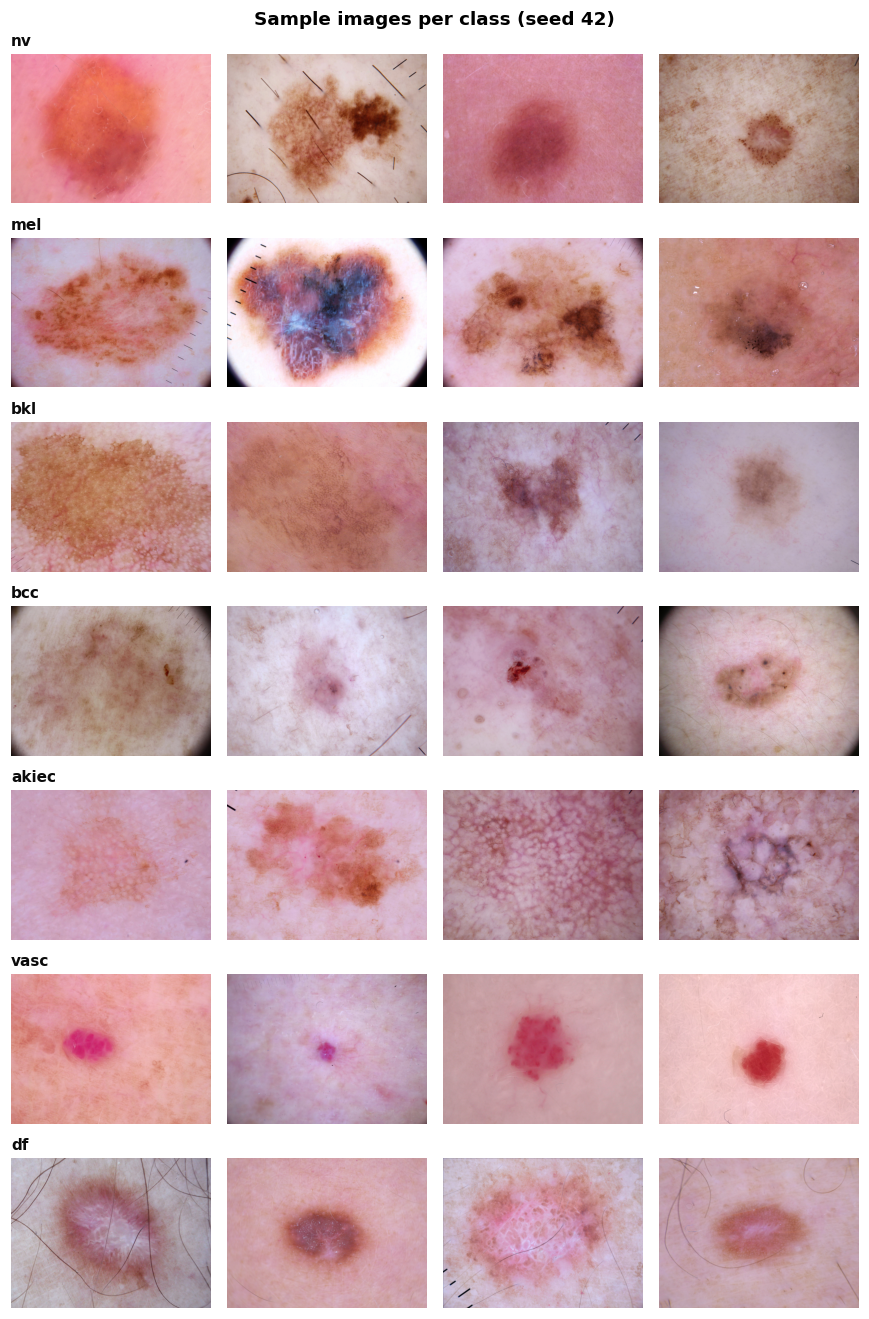

In [11]:
# Check 8: sample grid, 4 images per class
n_per_class = 4
classes = list(counts.index)
fig, axes = plt.subplots(len(classes), n_per_class, figsize=(n_per_class * 2.0, len(classes) * 1.75))
axes = np.atleast_2d(axes)
for r, cls in enumerate(classes):
    pool = meta.loc[meta["dx"] == cls, "image_id"]
    picks = pool.sample(n=min(n_per_class, len(pool)), random_state=SEED).tolist()
    for c in range(n_per_class):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks) and picks[c] in images:
            with Image.open(images[picks[c]][0]) as img:
                ax.imshow(img.convert("RGB"))
        if c == 0:
            ax.set_title(f"{cls}", loc="left", fontsize=10, color=INK)
fig.suptitle("Sample images per class (seed 42)", fontweight="bold")
plt.tight_layout()
plt.show()

## Save the summary and read the verdict
Saves every fact above to `phase1_summary.json` and prints the result for D1, D2 and D3. The verdict lines only state what the numbers show; the team still reviews them before the tracker items are marked Done.

In [12]:
# Save + verdict
out = Path("phase1_summary.json")
out.write_text(json.dumps(SUMMARY, indent=2))

imperfections = []
if SUMMARY["imbalance_ratio"] > 1.5:
    imperfections.append(f"class imbalance (ratio {SUMMARY['imbalance_ratio']})")
missing_any = sum(SUMMARY["missing_values"].values()) + sum(SUMMARY["unknown_values"].values())
if missing_any:
    imperfections.append(f"missing or 'unknown' metadata values ({missing_any})")
if len(sizes) > 1:
    imperfections.append(f"{len(sizes)} different image sizes")
if dup_groups or dup_rows:
    imperfections.append("duplicated records")
if multi:
    imperfections.append(f"{multi} lesions with several photos (group split needed)")

print("D1  unique images >= 5,000 :", SUMMARY["unique_image_ids"], "->", "MET" if SUMMARY["unique_image_ids"] >= 5000 else "NOT MET")
print("D2  classes >= 3           :", SUMMARY["n_classes"], "->", "MET" if SUMMARY["n_classes"] >= 3 else "NOT MET")
print("D3  imperfections found    :", "; ".join(imperfections) if imperfections else "none found -> NOT MET")
print()
print("Saved:", out.resolve())

D1  unique images >= 5,000 : 10015 -> MET
D2  classes >= 3           : 7 -> MET
D3  imperfections found    : class imbalance (ratio 58.3); missing or 'unknown' metadata values (348); duplicated records; 1956 lesions with several photos (group split needed)

Saved: /content/phase1_summary.json


## Next steps
1. Send the outputs of every cell (or a screenshot of each) and `phase1_summary.json` for review.
2. After review, the tracker items D1, D2 and D3 are marked Done with this notebook as evidence.
3. The numbers here feed the problem statement (P1), the metric justification (P2) and, in Phase 2, the group split design in `src/data.py`.